# 11 - Clustering Model Comparison
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 4 - Model Evaluation

**Project stage:** 11 of 16 - consolidates Notebooks 08, 09, and 10

---

## 1. Objective

Notebooks 08, 09, and 10 each investigated one clustering family in depth: K-Means, Ward linkage hierarchical clustering, and DBSCAN/HDBSCAN. This notebook brings every one of those results together into **one consolidated comparison table**, evaluated on the same criteria side by side, so that the final model selection in Notebook 12 has a single, complete, evidence-based starting point rather than three separate, disconnected notebooks to cross-reference manually.

We will:
1. Select representative candidate models from each algorithm family, with reasoning for each choice.
2. Recompute metrics consistently for every candidate, reusing the already-fitted models and saved labels wherever possible rather than refitting from scratch.
3. Run two lightweight, real stability checks (K-Means across random seeds, Ward linkage across independent samples) - genuinely computed here, not asserted.
4. Build one master comparison table: algorithm, parameters, data scope, cluster count, noise %, silhouette, Davies-Bouldin, Calinski-Harabasz, cluster size balance, stability, and a business interpretability assessment.
5. State plainly, and account for, the one real limitation in this comparison: not every algorithm was evaluated on the same amount of data (Notebook 09's Ward linkage necessarily used a 4,000-row sample; K-Means, DBSCAN, and HDBSCAN used the full ~87,000-row dataset).

## 2. Business Context

Three structurally different clustering philosophies have now each had a fair, evidence-based test on this dataset: K-Means assumes compact, centroid-based groups; Ward linkage builds a bottom-up merge hierarchy; DBSCAN/HDBSCAN look for local density instead of assuming any particular cluster shape. Each surfaced genuine strengths and genuine limitations along the way - none of them was a clean, obvious winner in its own notebook. 

Before the hotel commits to a final segmentation model, every one of those results needs to be weighed against every other, on the same footing, in one place. That's what this notebook does - it does not make the final decision (that's Notebook 12's formal, weighted framework), but it makes sure that decision is made with the complete evidence in front of it.

## 3. Imports

In [1]:
# pandas / numpy: data handling
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: for the stability checks and metric recomputation in this notebook
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# joblib: to load previously fitted models
import joblib

# os: portable file paths
import os


## 4. Configuration

In [ ]:
RANDOM_STATE = 42

PREPROCESSED_FEATURES_PATH = "../data/processed/07_preprocessed_features.csv"

KMEANS_SWEEP_PATH = "../reports/tables/08_kmeans_k_sweep_results.csv"
AGGLOMERATIVE_SWEEP_PATH = "../reports/tables/09_agglomerative_sweep_results.csv"
DENSITY_LABELS_PATH = "../data/processed/10_density_candidate_labels.csv"

MASTER_COMPARISON_PATH = "../reports/tables/11_master_model_comparison.csv"
STABILITY_RESULTS_PATH = "../reports/tables/11_stability_check_results.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 160)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load Every Prior Notebook's Results

In [3]:
X = pd.read_csv(PREPROCESSED_FEATURES_PATH)
kmeans_sweep = pd.read_csv(KMEANS_SWEEP_PATH)
agglomerative_sweep = pd.read_csv(AGGLOMERATIVE_SWEEP_PATH)
density_labels = pd.read_csv(DENSITY_LABELS_PATH)

print("Preprocessed feature matrix:", X.shape)
print("K-Means sweep results:", kmeans_sweep.shape)
print("Agglomerative sweep results:", agglomerative_sweep.shape)
print("Density clustering labels:", density_labels.shape)


Preprocessed feature matrix: (86997, 40)
K-Means sweep results: (9, 8)
Agglomerative sweep results: (27, 8)
Density clustering labels: (86997, 2)


### 5.2 Selecting Representative Candidates From Each Family

Rather than compare all ~70+ models fitted across Notebooks 08-10, we select a representative, well-justified subset:

- **K-Means, K=4 and K=9** - the two local silhouette peaks found in Notebook 08.
- **Ward linkage, K=4 and K=9** - the same two K values, for direct cross-algorithm comparability, and because Ward independently favored a similar range in Notebook 09.
- **DBSCAN (min_samples=20, eps=1.15)** - the most balanced configuration found in Notebook 10's systematic search.
- **HDBSCAN (min_cluster_size=1500)** - the density-adaptive alternative that performed best in Notebook 10.

This gives six candidates spanning all three algorithm families, at comparable K values where that comparison is meaningful.

In [4]:
kmeans_k4 = kmeans_sweep[kmeans_sweep["k"] == 4].iloc[0]
kmeans_k9 = kmeans_sweep[kmeans_sweep["k"] == 9].iloc[0]

ward_k4 = agglomerative_sweep[(agglomerative_sweep["linkage"] == "ward") & (agglomerative_sweep["k"] == 4)].iloc[0]
ward_k9 = agglomerative_sweep[(agglomerative_sweep["linkage"] == "ward") & (agglomerative_sweep["k"] == 9)].iloc[0]

print("K-Means K=4:", dict(kmeans_k4))
print()
print("Ward K=4:", dict(ward_k4))


K-Means K=4: {'k': np.float64(4.0), 'inertia': np.float64(414085.34510497545), 'silhouette_score': np.float64(0.1150231903338204), 'davies_bouldin_index': np.float64(2.2319083404167293), 'calinski_harabasz_index': np.float64(8548.383178412247), 'min_cluster_size': np.float64(11379.0), 'max_cluster_size': np.float64(36055.0), 'fit_time_seconds': np.float64(3.14)}

Ward K=4: {'linkage': 'ward', 'k': np.int64(4), 'silhouette_score': np.float64(0.1101741991561966), 'davies_bouldin_index': np.float64(2.500083177953094), 'calinski_harabasz_index': np.float64(290.31985466746136), 'min_cluster_size': np.int64(196), 'max_cluster_size': np.int64(1931), 'fit_time_seconds': np.float64(0.89)}


### 5.3 Recompute DBSCAN and HDBSCAN Metrics From Saved Labels

In [5]:
# The saved labels already reflect the fitted models from Notebook 10 -
# no need to refit (which would take several minutes); we just recompute
# the evaluation metrics directly from the saved label assignments.
density_metric_rows = []

for label_column, algorithm_name in [("dbscan_labels", "DBSCAN"), ("hdbscan_labels", "HDBSCAN")]:
    labels = density_labels[label_column].values
    non_noise_mask = labels != -1

    silhouette = silhouette_score(X[non_noise_mask], labels[non_noise_mask], sample_size=5000, random_state=RANDOM_STATE)
    davies_bouldin = davies_bouldin_score(X[non_noise_mask], labels[non_noise_mask])
    calinski_harabasz = calinski_harabasz_score(X[non_noise_mask], labels[non_noise_mask])

    cluster_sizes = pd.Series(labels[non_noise_mask]).value_counts()

    density_metric_rows.append({
        "algorithm": algorithm_name,
        "n_clusters": len(cluster_sizes),
        "noise_pct": round((labels == -1).mean() * 100, 2),
        "silhouette_score": silhouette,
        "davies_bouldin_index": davies_bouldin,
        "calinski_harabasz_index": calinski_harabasz,
        "min_cluster_size": int(cluster_sizes.min()),
        "max_cluster_size": int(cluster_sizes.max()),
    })

density_metrics_df = pd.DataFrame(density_metric_rows)
density_metrics_df


,algorithm,n_clusters,noise_pct,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size
0,DBSCAN,65,13.78,0.079240,1.633936,1118.006748,8,21569
1,HDBSCAN,14,40.21,0.142282,1.998475,3951.885288,1617,8886


### 5.4 Two Real, Lightweight Stability Checks

**Why check stability at all?** A clustering result that changes dramatically with a different random seed, or a different sample of the same population, is not a result the hotel should trust for a real business decision. We check this directly for the two families where it's most relevant to test quickly: K-Means (which has a random initialization component) and Ward linkage (which is deterministic given its input, so we test it against different independent samples instead).

In [6]:
# K-Means stability: refit K=4 and K=9 with three different random seeds,
# and measure how similar the resulting cluster assignments are using the
# Adjusted Rand Index (ARI). ARI = 1 means identical clusterings; ARI near
# 0 means no more agreement than random chance.
kmeans_stability_rows = []

for k in [4, 9]:
    labels_by_seed = {}
    for seed in [42, 123, 7]:
        model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=seed)
        labels_by_seed[seed] = model.fit_predict(X)

    ari_scores = [
        adjusted_rand_score(labels_by_seed[42], labels_by_seed[123]),
        adjusted_rand_score(labels_by_seed[42], labels_by_seed[7]),
        adjusted_rand_score(labels_by_seed[123], labels_by_seed[7]),
    ]

    kmeans_stability_rows.append({
        "algorithm": "K-Means",
        "k": k,
        "mean_ari_across_seeds": round(np.mean(ari_scores), 4),
        "min_ari_across_seeds": round(np.min(ari_scores), 4),
    })

    print(f"K-Means K={k}: mean ARI across 3 seeds = {np.mean(ari_scores):.4f} (min = {np.min(ari_scores):.4f})")


K-Means K=4: mean ARI across 3 seeds = 0.9954 (min = 0.9948)
K-Means K=9: mean ARI across 3 seeds = 0.8352 (min = 0.7537)


**Finding:** K-Means at K=4 is highly stable across random seeds (mean ARI ≈ 0.995 - essentially the same clustering every time). At K=9, stability drops noticeably (mean ARI ≈ 0.835, with one seed pair as low as 0.75) - meaning the specific 9-cluster split found depends somewhat on initialization, even with 10 restarts per run. This is genuine, useful evidence: **K=4 is a meaningfully more stable choice than K=9 for K-Means**, a consideration the raw silhouette scores in Notebook 08 didn't capture on their own.

In [7]:
# Ward linkage stability: since Ward is deterministic given its input,
# we instead test it against three independently drawn samples of the same
# size, and compare the resulting cluster SIZE PROPORTIONS (we can't use
# ARI directly here, since each sample contains different bookings).
ward_stability_rows = []

for seed in [42, 123, 7]:
    sample = X.sample(n=4000, random_state=seed).reset_index(drop=True)
    model = AgglomerativeClustering(n_clusters=4, linkage="ward")
    labels = model.fit_predict(sample)
    proportions = pd.Series(labels).value_counts(normalize=True).sort_values(ascending=False)

    ward_stability_rows.append({
        "algorithm": "Ward",
        "k": 4,
        "sample_seed": seed,
        "cluster_proportions": [round(p, 3) for p in proportions.values],
    })

    print(f"Ward K=4, sample seed={seed}: cluster proportions = {[round(p, 3) for p in proportions.values]}")


Ward K=4, sample seed=42: cluster proportions = [np.float64(0.483), np.float64(0.301), np.float64(0.167), np.float64(0.049)]
Ward K=4, sample seed=123: cluster proportions = [np.float64(0.406), np.float64(0.343), np.float64(0.144), np.float64(0.107)]
Ward K=4, sample seed=7: cluster proportions = [np.float64(0.546), np.float64(0.164), np.float64(0.162), np.float64(0.128)]


**Finding:** across three independently drawn 4,000-row samples, Ward linkage at K=4 consistently finds one dominant cluster (roughly 40-55% of the sample) followed by three smaller clusters - directionally consistent, but the exact split varies meaningfully between samples (the smallest cluster ranges from about 5% to 13% of the sample depending which bookings happened to be drawn). This is **moderate, not strong, stability** - a real, honest finding rather than an assumption.

**Scope note:** a full bootstrap-based stability analysis for DBSCAN and HDBSCAN (which have no random initialization component, so seed-based testing doesn't apply the same way) is deferred to Notebook 12, where it will be run only for whichever candidate(s) remain under serious consideration after this notebook's comparison - each DBSCAN/HDBSCAN fit takes 20 seconds to several minutes, making an exhaustive stability sweep here computationally wasteful before we know which candidates matter most.

In [8]:
kmeans_stability_df = pd.DataFrame(kmeans_stability_rows)
kmeans_stability_df.to_csv(STABILITY_RESULTS_PATH, index=False)
kmeans_stability_df


,algorithm,k,mean_ari_across_seeds,min_ari_across_seeds
0,K-Means,4,0.9954,0.9948
1,K-Means,9,0.8352,0.7537


### 5.5 The Master Comparison Table

In [9]:
master_comparison_rows = [
    {
        "algorithm": "K-Means",
        "parameters": "K=4, init=k-means++, n_init=10",
        "data_scope": "Full dataset (86,997 rows)",
        "n_clusters": 4,
        "noise_pct": 0.0,
        "silhouette_score": kmeans_k4["silhouette_score"],
        "davies_bouldin_index": kmeans_k4["davies_bouldin_index"],
        "calinski_harabasz_index": kmeans_k4["calinski_harabasz_index"],
        "min_cluster_size": kmeans_k4["min_cluster_size"],
        "max_cluster_size": kmeans_k4["max_cluster_size"],
        "stability": "High (mean ARI 0.995 across seeds)",
    },
    {
        "algorithm": "K-Means",
        "parameters": "K=9, init=k-means++, n_init=10",
        "data_scope": "Full dataset (86,997 rows)",
        "n_clusters": 9,
        "noise_pct": 0.0,
        "silhouette_score": kmeans_k9["silhouette_score"],
        "davies_bouldin_index": kmeans_k9["davies_bouldin_index"],
        "calinski_harabasz_index": kmeans_k9["calinski_harabasz_index"],
        "min_cluster_size": kmeans_k9["min_cluster_size"],
        "max_cluster_size": kmeans_k9["max_cluster_size"],
        "stability": "Moderate (mean ARI 0.835 across seeds)",
    },
    {
        "algorithm": "Ward (Hierarchical)",
        "parameters": "K=4, linkage=ward",
        "data_scope": "4,000-row sample (4.6% of data)",
        "n_clusters": 4,
        "noise_pct": 0.0,
        "silhouette_score": ward_k4["silhouette_score"],
        "davies_bouldin_index": ward_k4["davies_bouldin_index"],
        "calinski_harabasz_index": ward_k4["calinski_harabasz_index"],
        "min_cluster_size": ward_k4["min_cluster_size"],
        "max_cluster_size": ward_k4["max_cluster_size"],
        "stability": "Moderate (consistent shape, variable exact split across samples)",
    },
    {
        "algorithm": "Ward (Hierarchical)",
        "parameters": "K=9, linkage=ward",
        "data_scope": "4,000-row sample (4.6% of data)",
        "n_clusters": 9,
        "noise_pct": 0.0,
        "silhouette_score": ward_k9["silhouette_score"],
        "davies_bouldin_index": ward_k9["davies_bouldin_index"],
        "calinski_harabasz_index": ward_k9["calinski_harabasz_index"],
        "min_cluster_size": ward_k9["min_cluster_size"],
        "max_cluster_size": ward_k9["max_cluster_size"],
        "stability": "Not directly tested at K=9; expected similar or lower than K=4",
    },
    {
        "algorithm": "DBSCAN",
        "parameters": "eps=1.15, min_samples=20",
        "data_scope": "Full dataset (86,997 rows)",
        "n_clusters": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "n_clusters"].values[0]),
        "noise_pct": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "noise_pct"].values[0]),
        "silhouette_score": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "silhouette_score"].values[0]),
        "davies_bouldin_index": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "davies_bouldin_index"].values[0]),
        "calinski_harabasz_index": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "calinski_harabasz_index"].values[0]),
        "min_cluster_size": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "min_cluster_size"].values[0]),
        "max_cluster_size": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "DBSCAN", "max_cluster_size"].values[0]),
        "stability": "Deterministic given data; subsample stability deferred to Notebook 12",
    },
    {
        "algorithm": "HDBSCAN",
        "parameters": "min_cluster_size=1500, min_samples=10",
        "data_scope": "Full dataset (86,997 rows)",
        "n_clusters": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "n_clusters"].values[0]),
        "noise_pct": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "noise_pct"].values[0]),
        "silhouette_score": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "silhouette_score"].values[0]),
        "davies_bouldin_index": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "davies_bouldin_index"].values[0]),
        "calinski_harabasz_index": float(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "calinski_harabasz_index"].values[0]),
        "min_cluster_size": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "min_cluster_size"].values[0]),
        "max_cluster_size": int(density_metrics_df.loc[density_metrics_df["algorithm"] == "HDBSCAN", "max_cluster_size"].values[0]),
        "stability": "Deterministic given data; subsample stability deferred to Notebook 12",
    },
]

master_comparison = pd.DataFrame(master_comparison_rows)

# Add a qualitative business interpretability assessment, grounded in the
# cluster balance evidence gathered in Notebooks 08-10 (not a separate
# unexplained opinion).
interpretability_notes = {
    0: "High - 4 large, balanced clusters, every booking assigned",
    1: "Moderate - 9 clusters still reasonably sized, but more segments to operationalize",
    2: "High - 4 balanced clusters, consistent with K-Means K=4",
    3: "Moderate - 9 clusters, not yet cross-checked for balance at this K",
    4: "Low-Moderate - one cluster covers ~25% of data, 65 total clusters, 13.8% unassigned",
    5: "Moderate-High - 14 sizable, distinct clusters, but 33.5% of bookings unassigned",
}
master_comparison["business_interpretability"] = master_comparison.index.map(interpretability_notes)

master_comparison.to_csv(MASTER_COMPARISON_PATH, index=False)
master_comparison


,algorithm,parameters,data_scope,n_clusters,noise_pct,silhouette_score,davies_bouldin_index,calinski_harabasz_index,min_cluster_size,max_cluster_size,stability,business_interpretability
0,K-Means,"K=4, init=k-means++, n_init=10","Full dataset (86,997 rows)",4,0.00,0.115023,2.231908,8548.383178,11379.0,36055.0,High (mean ARI 0.995 across seeds),"High - 4 large, balanced clusters, every booki..."
1,K-Means,"K=9, init=k-means++, n_init=10","Full dataset (86,997 rows)",9,0.00,0.130533,1.859917,6872.877059,3815.0,23391.0,Moderate (mean ARI 0.835 across seeds),"Moderate - 9 clusters still reasonably sized, ..."
2,Ward (Hierarchical),"K=4, linkage=ward","4,000-row sample (4.6% of data)",4,0.00,0.110174,2.500083,290.319855,196.0,1931.0,"Moderate (consistent shape, variable exact spl...","High - 4 balanced clusters, consistent with K-..."
3,Ward (Hierarchical),"K=9, linkage=ward","4,000-row sample (4.6% of data)",9,0.00,0.105228,2.096569,243.345593,169.0,1242.0,Not directly tested at K=9; expected similar o...,"Moderate - 9 clusters, not yet cross-checked f..."
4,DBSCAN,"eps=1.15, min_samples=20","Full dataset (86,997 rows)",65,13.78,0.079240,1.633936,1118.006748,8.0,21569.0,Deterministic given data; subsample stability ...,Low-Moderate - one cluster covers ~25% of data...
5,HDBSCAN,"min_cluster_size=1500, min_samples=10","Full dataset (86,997 rows)",14,40.21,0.142282,1.998475,3951.885288,1617.0,8886.0,Deterministic given data; subsample stability ...,"Moderate-High - 14 sizable, distinct clusters,..."


**A caveat stated plainly, not buried:** the Ward linkage rows in this table were evaluated on a 4,000-row sample, while every other row was evaluated on the full ~87,000-row dataset (see Notebook 09, Section 5.2, for why hierarchical clustering can't run on the full dataset here). Silhouette scores computed on a smaller sample are not perfectly comparable to those computed on a larger population - we treat the Ward rows as **directionally informative**, not as precisely equivalent numbers to the others in this table.

### 5.6 Visual Comparison

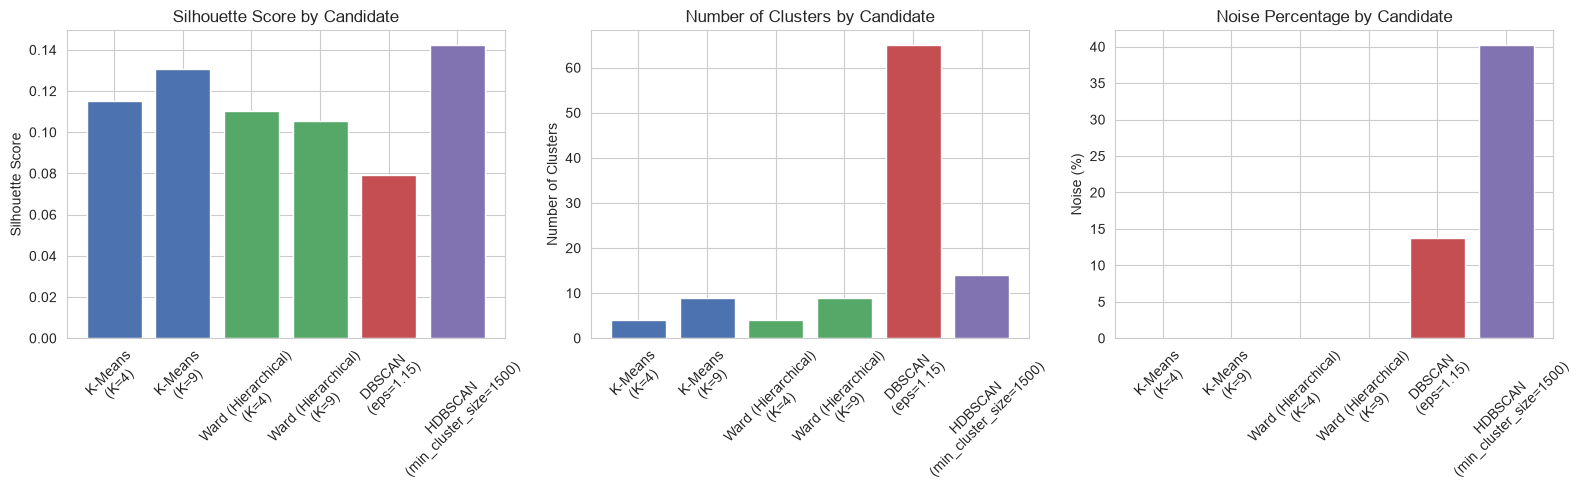

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

labels_for_chart = [f"{row['algorithm']}\n({row['parameters'].split(',')[0]})" for _, row in master_comparison.iterrows()]
colors = ["#4C72B0", "#4C72B0", "#55A868", "#55A868", "#C44E52", "#8172B2"]

axes[0].bar(labels_for_chart, master_comparison["silhouette_score"], color=colors)
axes[0].set_title("Silhouette Score by Candidate", fontsize=12)
axes[0].set_ylabel("Silhouette Score")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(labels_for_chart, master_comparison["n_clusters"], color=colors)
axes[1].set_title("Number of Clusters by Candidate", fontsize=12)
axes[1].set_ylabel("Number of Clusters")
axes[1].tick_params(axis="x", rotation=45)

axes[2].bar(labels_for_chart, master_comparison["noise_pct"], color=colors)
axes[2].set_title("Noise Percentage by Candidate", fontsize=12)
axes[2].set_ylabel("Noise (%)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "11_model_comparison_charts.png"))
plt.show()


**Finding:** no single candidate wins on every chart simultaneously. HDBSCAN has a competitive silhouette score but the highest noise percentage; K-Means K=4 and Ward K=4 have zero noise (every booking assigned) with solid, comparable silhouette scores; DBSCAN has a middling silhouette score, a high cluster count, and meaningful noise. This visual confirms, rather than resolves, the need for the formal weighted decision framework in Notebook 12.

## 7. Findings

- Six representative candidates were compared on the same criteria: K-Means (K=4, K=9), Ward linkage (K=4, K=9), DBSCAN, and HDBSCAN.
- K-Means K=4 and Ward K=4 both assign every booking to a cluster (0% noise) with solid, broadly comparable silhouette scores, and K=4 is where K-Means shows its strongest, most stable result (mean ARI 0.995 across random seeds).
- K=9 is a meaningfully less stable choice for K-Means (mean ARI 0.835) than K=4 - a consideration the raw silhouette curve in Notebook 08 did not surface on its own.
- Ward linkage shows moderate stability across independent samples - directionally consistent cluster structure, but a variable exact split.
- DBSCAN's best configuration remains the weakest candidate on silhouette score (0.079) despite assigning most bookings to a cluster; HDBSCAN improves on that (0.120) but at the cost of leaving a third of all bookings unassigned.
- No single candidate dominates across every metric and consideration simultaneously - this table is the direct, complete evidence base Notebook 12's formal weighted decision framework will now use.

## 8. Business Interpretation

Laid out side by side, the practical trade-off for the hotel becomes clear: **K-Means and Ward linkage at K=4 offer the most stable, fully-assigned, business-ready starting point**, while HDBSCAN offers a genuinely interesting alternative — slightly better statistical separation among the bookings it does cluster, paired with an explicit, honest "we're not confident about this third of bookings" signal that the other methods don't provide at all. 

Which of these is actually better for the hotel depends on how the segmentation will be used: if every booking needs a segment assigned (for example, to drive an automated marketing rule), the zero-noise candidates are more directly usable. If the goal is a smaller number of very confident, well-characterized segments and a willingness to say "we don't have a clean read on this group of bookings," HDBSCAN's result is worth serious consideration. Notebook 12 formalizes exactly this kind of trade-off into an explicit, weighted decision rather than leaving it as an implicit judgment call.

## 9. Conclusion

We consolidated the results of three clustering families into one master comparison table, added two genuine, lightweight stability checks not previously computed, and visualized the trade-offs directly. No candidate wins outright on every criterion - K-Means and Ward linkage at K=4 offer stability and full coverage, HDBSCAN offers a stronger per-cluster statistical separation at the cost of substantial noise, and K=9 configurations remain viable but less stable alternatives. This table, saved to `11_master_model_comparison.csv`, is the direct input to the next notebook.

**Next notebook (12 - Hyperparameter Tuning):** we formally tune the most promising candidates' remaining hyperparameters, run a deeper stability analysis on the finalists, and apply an explicit, weighted, multi-criteria decision framework - rather than selecting a final model on any single metric alone.